# HNCC Resource Plots

This notebook reads precomputed HNCC resource data and redraws the resource figures. The first code cell prints the active system size and accumulated 1-norm cap, then chooses the output suffix from the data metadata: `_N8_1.75`, `_N8_e`, `_N10_1.75`, or `_N10_e`.

The middle panel reports synthesized $T$-gate counts rather than raw $R_z$ counts.


In [1]:
from __future__ import annotations

import json
import math
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator, LogLocator
%config InlineBackend.figure_format = 'retina'
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 16
plt.rcParams['text.usetex'] = False
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['mathtext.rm'] = 'STIXGeneral'
plt.rcParams['mathtext.it'] = 'STIXGeneral:italic'
plt.rcParams['mathtext.bf'] = 'STIXGeneral:bold'
plt.rcParams['pdf.fonttype'] = 3
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "resource").exists() and (ROOT.parent / "resource").exists():
    ROOT = ROOT.parent
RESOURCE_DIR = ROOT / "resource"

# N=8, cap=1.75
DEFAULT_DATA_PATH = RESOURCE_DIR / "data" / "hncc_resource_data_N8_cap_1.75.json"

# N=10, cap=1.75
DEFAULT_DATA_PATH = RESOURCE_DIR / "data" / "hncc_resource_data_N10.json"

# N=8, cap=e
DEFAULT_DATA_PATH = RESOURCE_DIR / "data" / "hncc_resource_data_N8_cap_e.json"

# N=10, cap=e
DEFAULT_DATA_PATH = RESOURCE_DIR / "data" / "hncc_resource_data_N10_cap_e.json"

DATA_PATH = Path(os.environ.get("HNCC_RESOURCE_DATA", DEFAULT_DATA_PATH))
FIGURE_DIR = ROOT / "figures"
T_SYNTHESIS_EPS = float(os.environ.get("HNCC_T_SYNTHESIS_EPS", "1e-15"))
T_SYNTHESIS_COST = float(os.environ.get("HNCC_T_SYNTHESIS_COST", 1.149 * math.log2(1.0 / T_SYNTHESIS_EPS) + 9.2))

if str(RESOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(RESOURCE_DIR))

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Missing {DATA_PATH}. Run: python resource/hncc_resource_collect.py")

with DATA_PATH.open("r", encoding="utf-8") as f:
    payload = json.load(f)

metadata = payload["metadata"]
eps_scan = payload.get("eps_scan", {})
time_scan = payload.get("time_scan", {})


def format_n_tag(values) -> str:
    values = [int(v) for v in values]
    if len(values) == 1:
        return f"N{values[0]}"
    return "N" + "_".join(str(v) for v in values)


def format_cap_tag(value: float) -> str:
    value = float(value)
    if math.isclose(value, math.e, rel_tol=1e-10, abs_tol=1e-12):
        return "e"
    if math.isclose(value, 1.75, rel_tol=1e-10, abs_tol=1e-12):
        return "1.75"
    return f"{value:g}"

N_TAG = format_n_tag(metadata.get("n_values", []))
CAP_TAG = format_cap_tag(metadata.get("sampling_overhead_cap"))
FIGURE_TAG = os.environ.get("HNCC_FIGURE_TAG", f"_{N_TAG}_{CAP_TAG}")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"CONFIG: N={N_TAG[1:]}, 1-norm cap={CAP_TAG}")
print(f"data: {DATA_PATH}")
print(f"figure tag: {FIGURE_TAG!r}")
print(f"sampling_overhead_cap: {metadata.get('sampling_overhead_cap')}")
print(f"T synthesis cost per Rz: {T_SYNTHESIS_COST:.3f}")
metadata


CONFIG: N=10, 1-norm cap=e
data: /Users/AntiEntropy/Documents/Research/NCC Trotter Compensation/resource/data/hncc_resource_data_N10_cap_e.json
figure tag: '_N10_e'
sampling_overhead_cap: 2.718281828459045
T synthesis cost per Rz: 66.453


{'eps': [0.001, 0.0008, 0.0006, 0.0004, 0.0003, 0.0002, 0.0001],
 'extrap_bases': [2, 4],
 'fixed_eps': 0.001,
 'hncc_orders': [2],
 'n_values': [10],
 'ncc_orders': [2],
 'num_x': 40,
 'orders': [2, 4, 6],
 'q0_by_order': {'2': 6},
 's0_by_order': {'2': 6},
 'sampling_overhead_cap': 2.718281828459045,
 'scan': 'both',
 'time': 1.0,
 'time_values': [0.25, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 2.8, 4.0],
 'x_max': 1.0,
 'x_min': 0.001}

In [2]:
def method_sort_key(method: str):
    if method == "Trotter" or method.startswith("S"):
        return (0, method)
    if method.startswith("RE"):
        return (1, method)
    if method.startswith("NCC"):
        return (2, method)
    if method.startswith("HNCC"):
        return (3, method)
    return (4, method)


def repetition_display_method(method: str) -> str:
    if method.startswith("S"):
        return "Trotter"
    return method


def legend_label(n_key: str, method: str, n_count: int) -> str:
    return method


def marker_for_method(method: str) -> str:
    if method == "Trotter" or method == "S2":
        return "--o"
    if method == "S4":
        return "-.s"
    if method == "S6":
        return ":^"
    if method.startswith("RE2"):
        return "--D"
    if method.startswith("RE4"):
        return "--P"
    if method == "NCC2":
        return "-.D"
    if method == "NCC4":
        return "-.P"
    if method == "HNCC2":
        return "-o"
    if method == "HNCC4":
        return "-s"
    return "-x"


def line_style_for_method(method: str):
    colors = {
        "Trotter": "#5f6368",
        "S2": "#5f6368",
        "S4": "#8c8c8c",
        "S6": "#b0b0b0",
        "RE2-3": "#1f77b4",
        "RE4-3": "#17becf",
        "NCC2": "#7b3294",
        "NCC4": "#984ea3",
        "HNCC2": "#d62728",
        "HNCC4": "#ff7f0e",
    }
    style = {
        "color": colors.get(method, "#333333"),
        "linewidth": 1.35,
        "alpha": 0.72,
    }
    if method.startswith("HNCC"):
        style.update({"linewidth": 2.35, "alpha": 1.0, "zorder": 5, "markeredgecolor": "white", "markeredgewidth": 0.45})
    elif method.startswith("NCC"):
        style.update({"linewidth": 1.65, "alpha": 0.88, "zorder": 4})
    elif method.startswith("RE"):
        style.update({"linewidth": 1.45, "alpha": 0.82, "zorder": 3})
    return style


def unique_legend(axs):
    by_label = {}
    for ax in axs:
        handles, labels = ax.get_legend_handles_labels()
        for handle, label in zip(handles, labels):
            by_label.setdefault(label, handle)
    return list(by_label.values()), list(by_label.keys())

Saved /Users/AntiEntropy/Documents/Research/NCC Trotter Compensation/figures/hncc_resource_tradeoff_vs_eps_N10_e.pdf


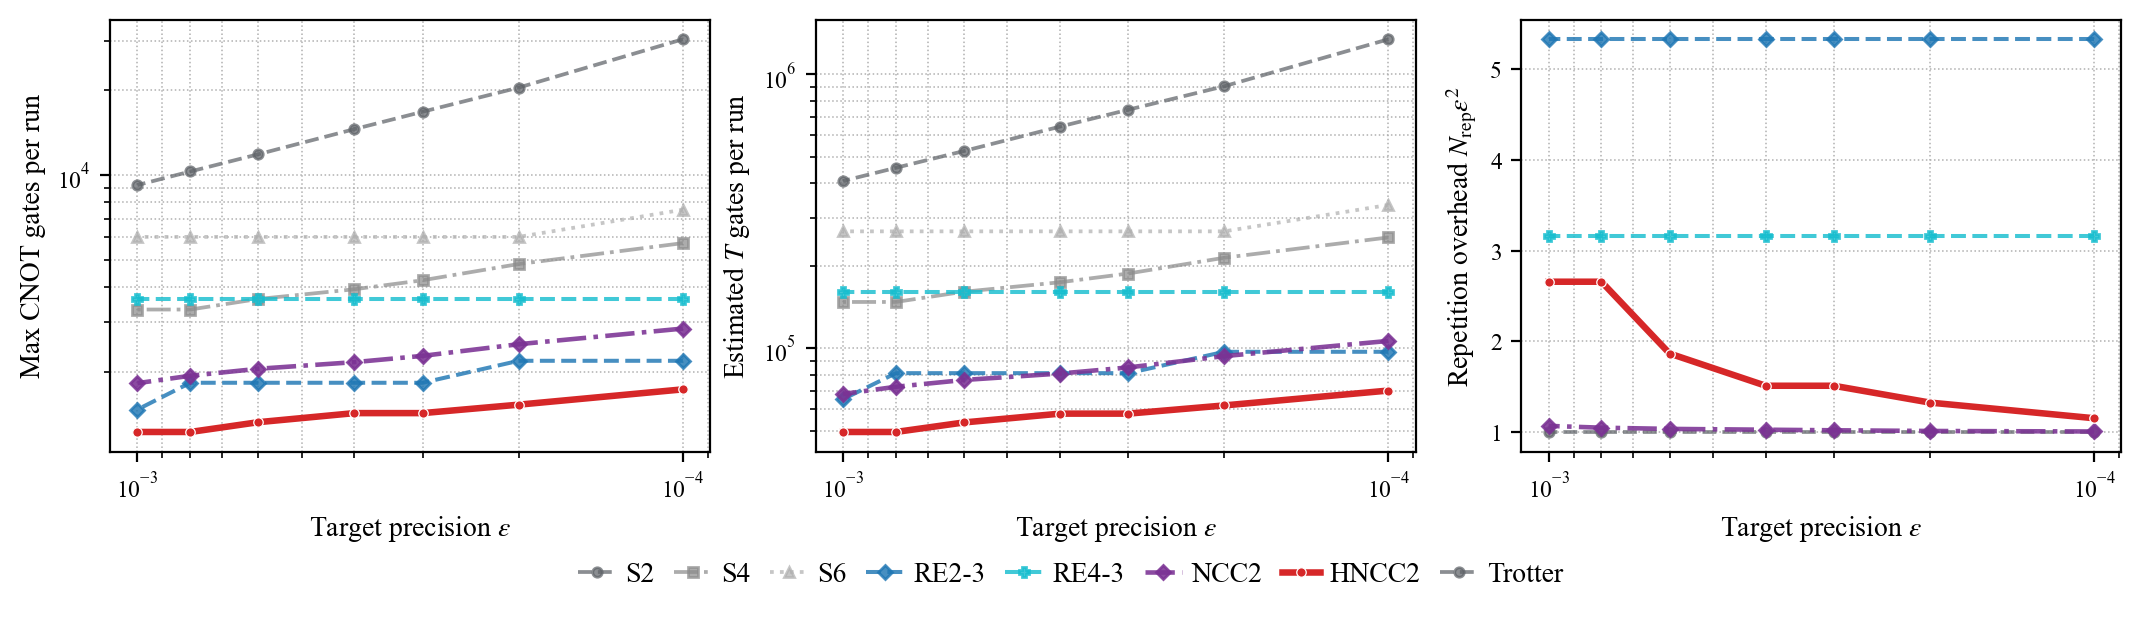

In [3]:
def max_t_gates(row: dict) -> float:
    return float(row["max_rz"]) * T_SYNTHESIS_COST


def make_eps_tradeoff_plot(eps_scan, eps_values, out_dir: Path):
    if not eps_scan:
        print("No eps_scan data in payload.")
        return None

    fig, (ax_cnot, ax_t, ax_rep) = plt.subplots(1, 3, figsize=(10.8, 3.2))
    eps_sorted = np.array(sorted(float(eps) for eps in eps_values), dtype=float)
    n_count = len(eps_scan)
    for n_key in sorted(eps_scan, key=lambda x: int(x)):
        rows = eps_scan[n_key]
        methods = sorted({row["method"] for row in rows}, key=method_sort_key)
        by_method = {method: {float(row["scan_value"]): row for row in rows if row["method"] == method} for method in methods}
        for method in methods:
            cnot_values = np.array([by_method[method][eps]["max_cnot"] for eps in eps_sorted])
            t_values = np.array([max_t_gates(by_method[method][eps]) for eps in eps_sorted])
            ax_cnot.loglog(eps_sorted, cnot_values, marker_for_method(method), ms=3.4, label=legend_label(n_key, method, n_count), **line_style_for_method(method))
            ax_t.loglog(eps_sorted, t_values, marker_for_method(method), ms=3.4, label=legend_label(n_key, method, n_count), **line_style_for_method(method))

        rep_methods = sorted({repetition_display_method(row["method"]) for row in rows}, key=method_sort_key)
        rep_by_method = {method: {} for method in rep_methods}
        for row in rows:
            rep_by_method[repetition_display_method(row["method"])].setdefault(float(row["scan_value"]), row)
        for method in rep_methods:
            values = np.array([rep_by_method[method][eps]["repetitions"] * eps**2 for eps in eps_sorted])
            ax_rep.semilogx(eps_sorted, values, marker_for_method(method), ms=3.4, label=legend_label(n_key, method, n_count), **line_style_for_method(method))

    ax_cnot.set_ylabel(r"Max CNOT gates per run")
    ax_t.set_ylabel(r"Estimated $T$ gates per run")
    ax_rep.set_ylabel(r"Repetition overhead $N_{\rm rep}\epsilon^2$")
    for ax in (ax_cnot, ax_t, ax_rep):
        ax.set_xlabel(r"Target precision $\epsilon$")
        ax.invert_xaxis()
        ax.grid(True, which="both", ls=":", lw=0.55)
        ax.tick_params(axis="both", labelsize=8.5)
        ax.xaxis.label.set_size(10)
        ax.yaxis.label.set_size(10)
        ax.set_box_aspect(0.72)
    handles, labels = unique_legend((ax_cnot, ax_t, ax_rep))
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.015), ncol=min(len(labels), 8), fontsize=10.0, frameon=False, handlelength=1.35, handletextpad=0.35, columnspacing=0.7, borderaxespad=0.0)
    fig.subplots_adjust(left=0.0553, right=0.9864, bottom=0.2448, top=0.9208, wspace=0.176)
    path = out_dir / f"hncc_resource_tradeoff_vs_eps{FIGURE_TAG}.pdf"
    fig.savefig(path)
    print(f"Saved {path}")
    return fig


fig_eps = make_eps_tradeoff_plot(eps_scan, metadata["eps"], FIGURE_DIR)
# fig_eps

Saved /Users/AntiEntropy/Documents/Research/NCC Trotter Compensation/figures/hncc_resource_tradeoff_vs_t_N10_e.pdf


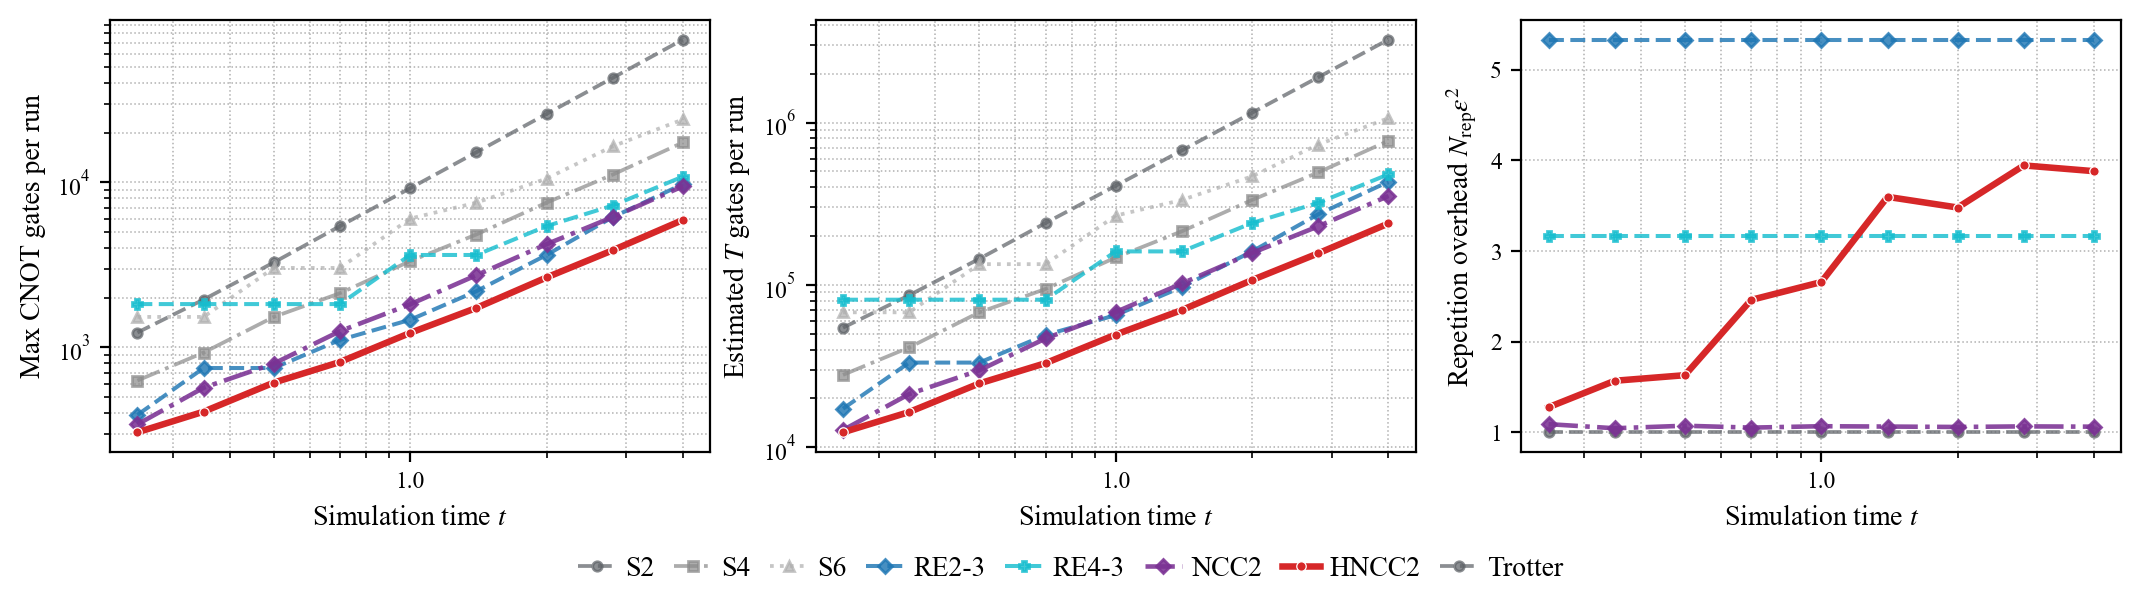

In [4]:
def format_time_axis(ax):
    ax.set_xscale("log")
    ax.set_xticks([1.0])
    ax.set_xticklabels(["1.0"])
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1))


def make_time_tradeoff_plot(time_scan, fixed_eps: float, out_dir: Path):
    if not time_scan:
        print("No time_scan data in payload.")
        return None

    times = np.array(sorted(float(key) for key in time_scan), dtype=float)
    all_rows = [row for rows in time_scan.values() for row in rows]
    methods = sorted({row["method"] for row in all_rows}, key=method_sort_key)
    rep_methods = sorted({repetition_display_method(row["method"]) for row in all_rows}, key=method_sort_key)

    fig, (ax_cnot, ax_t, ax_rep) = plt.subplots(1, 3, figsize=(10.8, 3.2))
    for method in methods:
        cnot_values = []
        t_values = []
        for time in times:
            rows = time_scan[str(float(time))]
            row = next(row for row in rows if row["method"] == method)
            cnot_values.append(row["max_cnot"])
            t_values.append(max_t_gates(row))
        ax_cnot.loglog(times, cnot_values, marker_for_method(method), ms=3.4, label=method, **line_style_for_method(method))
        ax_t.loglog(times, t_values, marker_for_method(method), ms=3.4, label=method, **line_style_for_method(method))

    for method in rep_methods:
        values = []
        for time in times:
            rows = time_scan[str(float(time))]
            row = next(row for row in rows if repetition_display_method(row["method"]) == method)
            values.append(row["repetitions"] * fixed_eps**2)
        ax_rep.semilogx(times, values, marker_for_method(method), ms=3.4, label=method, **line_style_for_method(method))

    ax_cnot.set_ylabel(r"Max CNOT gates per run")
    ax_t.set_ylabel(r"Estimated $T$ gates per run")
    ax_rep.set_ylabel(r"Repetition overhead $N_{\rm rep}\epsilon^2$")
    for ax in (ax_cnot, ax_t, ax_rep):
        ax.set_xlabel(r"Simulation time $t$")
        format_time_axis(ax)
        ax.grid(True, which="both", ls=":", lw=0.55)
        ax.tick_params(axis="both", labelsize=8.5)
        ax.xaxis.label.set_size(10)
        ax.yaxis.label.set_size(10)
        ax.set_box_aspect(0.72)
    handles, labels = unique_legend((ax_cnot, ax_t, ax_rep))
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.015), ncol=min(len(labels), 8), fontsize=10.0, frameon=False, handlelength=1.35, handletextpad=0.35, columnspacing=0.7, borderaxespad=0.0)
    fig.subplots_adjust(left=0.0553, right=0.9864, bottom=0.2354, top=0.9104, wspace=0.176)
    path = out_dir / f"hncc_resource_tradeoff_vs_t{FIGURE_TAG}.pdf"
    fig.savefig(path)
    print(f"Saved {path}")
    return fig


fig_time = make_time_tradeoff_plot(time_scan, metadata["fixed_eps"], FIGURE_DIR)
# fig_time